# Crude Oil Market & Inventory Forecasting — Model Evaluation

These notebooks contain the evaluation work for Sections 5.1 and 5.2.
The one-week-ahead inventory forecast is intentionally NOT included.

## 5.2 Baseline Comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Put this notebook inside your project/model-results folder, or change PROJECT below.
PROJECT = Path(".")

def find_file(name):
    matches = list(PROJECT.rglob(name))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {name}. Put the model-results folder inside this notebook folder."
        )
    return matches[0]


In [2]:
baseline = pd.read_csv(find_file("baseline_metrics.csv"))
display(baseline)


,Model,MAE (kb),RMSE (kb),R² Score
0,Naive (Persistence),4730.71,6360.17,-0.6868
1,Seasonal Naive (52-Wk),4800.43,6144.67,-0.5744
2,Historical Mean,3891.63,4897.55,-0.0002


In [3]:
baseline_table = pd.DataFrame({
    "Model": ["Naive (Persistence)", "Seasonal Naive (52-Wk)", "Historical Mean"],
    "MAE (kb)": [4730.71, 4800.43, 3891.63],
    "RMSE (kb)": [6360.17, 6144.67, 4897.55],
    "R²": [-0.6868, -0.5744, -0.0002],
    "Directional Accuracy (%)": [56.73, 57.69, 49.04]
})
display(baseline_table)


,Model,MAE (kb),RMSE (kb),R²,Directional Accuracy (%)
0,Naive (Persistence),4730.71,6360.17,-0.6868,56.73
1,Seasonal Naive (52-Wk),4800.43,6144.67,-0.5744,57.69
2,Historical Mean,3891.63,4897.55,-0.0002,49.04


In [4]:
advanced = pd.DataFrame({
    "Model": ["SARIMAX", "LightGBM", "LSTM"],
    "MAE (kb)": [3701.87, 3656.41, 3941.76],
    "RMSE (kb)": [4710.68, 4677.17, 4910.40],
    "R²": [0.0747, 0.0878, -0.0055],
    "Directional Accuracy (%)": [57.69, 59.62, 50.96]
})

comparison = pd.concat([baseline_table, advanced], ignore_index=True)
display(comparison.round(2))


,Model,MAE (kb),RMSE (kb),R²,Directional Accuracy (%)
0,Naive (Persistence),4730.71,6360.17,-0.69,56.73
1,Seasonal Naive (52-Wk),4800.43,6144.67,-0.57,57.69
2,Historical Mean,3891.63,4897.55,-0.00,49.04
3,SARIMAX,3701.87,4710.68,0.07,57.69
4,LightGBM,3656.41,4677.17,0.09,59.62
5,LSTM,3941.76,4910.40,-0.01,50.96


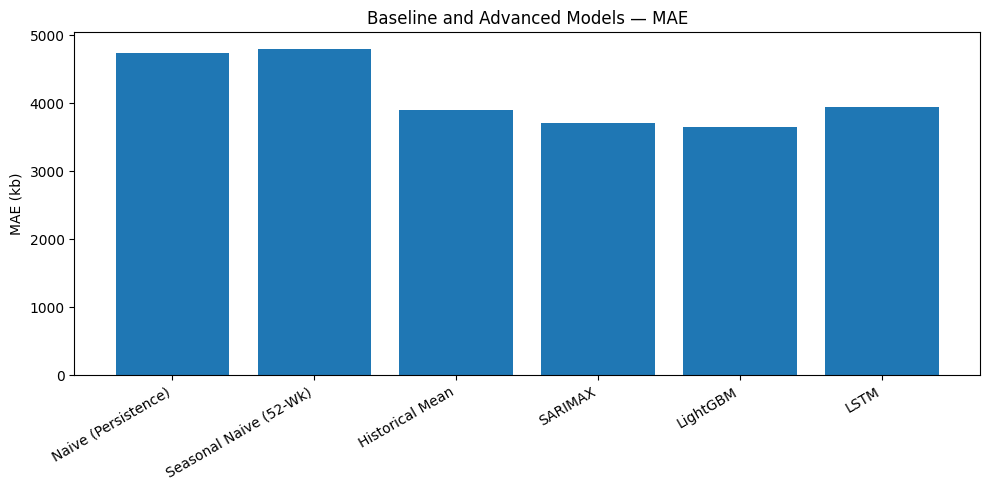

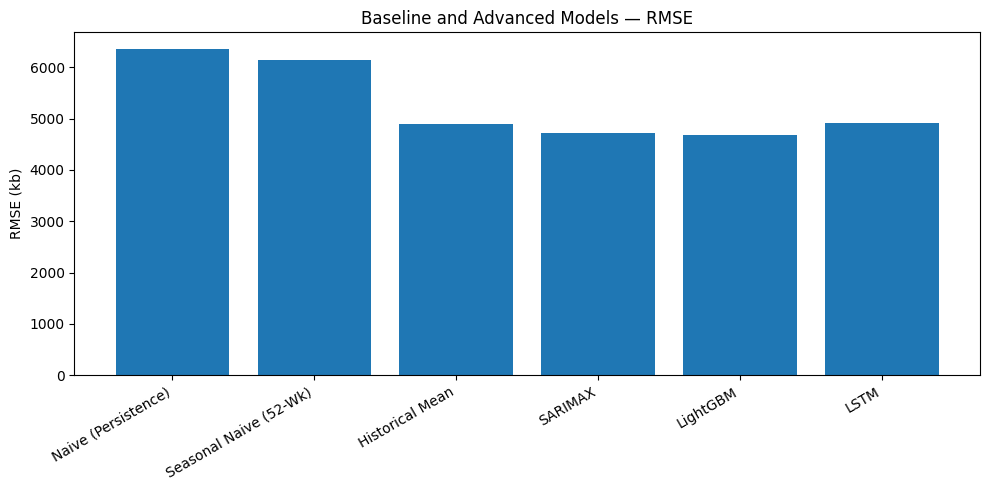

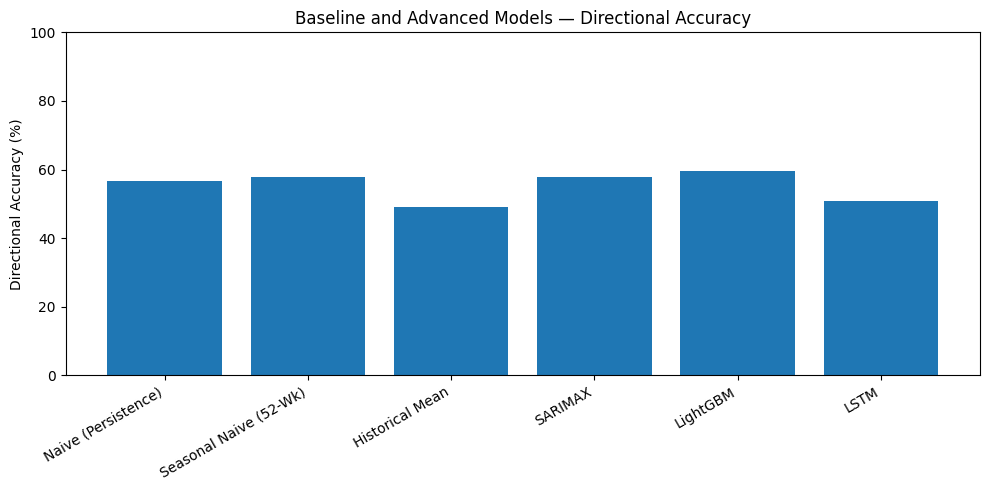

In [5]:
for metric, ylabel, title, ylim in [
    ("MAE (kb)", "MAE (kb)", "Baseline and Advanced Models — MAE", None),
    ("RMSE (kb)", "RMSE (kb)", "Baseline and Advanced Models — RMSE", None),
    ("Directional Accuracy (%)", "Directional Accuracy (%)",
     "Baseline and Advanced Models — Directional Accuracy", (0,100))
]:
    plt.figure(figsize=(10,5))
    plt.bar(comparison["Model"], comparison[metric])
    plt.ylabel(ylabel)
    plt.title(title)
    if ylim: plt.ylim(*ylim)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


### Baseline interpretation

The baseline models provide a reference point for assessing whether advanced forecasting methods add predictive value.

The Naive baseline achieved MAE = **4,730.71 kb** and RMSE = **6,360.17 kb**. The Seasonal Naive baseline achieved MAE = **4,800.43 kb** and RMSE = **6,144.67 kb**. The Historical Mean baseline achieved MAE = **3,891.63 kb** and RMSE = **4,897.55 kb**.

LightGBM achieved MAE = **3,656.41 kb**, RMSE = **4,677.17 kb**, and Directional Accuracy = **59.62%** on the same holdout period.


,Fold,Train_Size,Val_Size,MAE_kb,RMSE_kb,R2_Score,Directional_Acc_%
0,1,182,177,2826.478811,3575.567921,0.075155,58.757062
1,2,359,177,2984.241773,3747.250304,0.138879,63.841808
2,3,536,177,3621.270099,4624.188360,0.066252,67.796610
3,4,713,177,4637.029776,5834.539131,0.072007,58.757062
4,5,890,177,4026.010235,5130.580758,0.089566,63.276836


Mean MAE: 3619.01 kb
Mean RMSE: 4582.43 kb
Mean Directional Accuracy: 62.49%


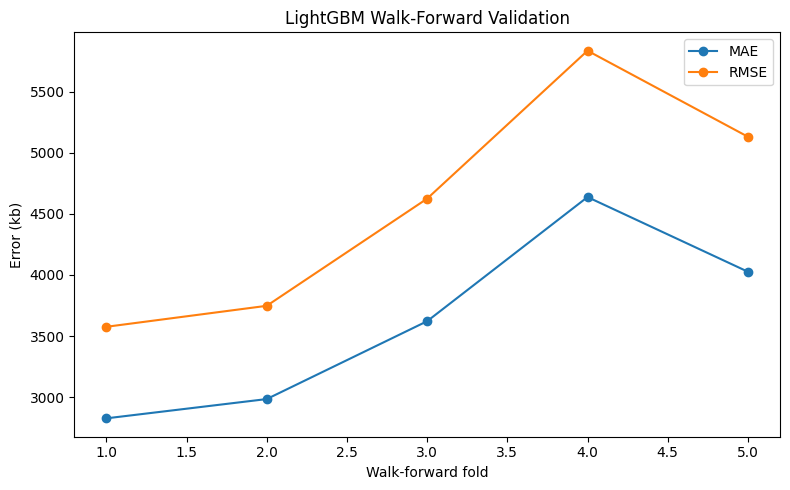

In [6]:
# Walk-forward validation
wf = pd.read_csv(find_file("walk_forward_lightgbm_summary.csv"))
display(wf)

mae_col = "MAE_kb"
rmse_col = "RMSE_kb"
da_col = "Directional_Acc_%"

print(f"Mean MAE: {wf[mae_col].mean():.2f} kb")
print(f"Mean RMSE: {wf[rmse_col].mean():.2f} kb")
print(f"Mean Directional Accuracy: {wf[da_col].mean():.2f}%")

plt.figure(figsize=(8,5))
plt.plot(wf["Fold"], wf[mae_col], marker="o", label="MAE")
plt.plot(wf["Fold"], wf[rmse_col], marker="o", label="RMSE")
plt.xlabel("Walk-forward fold")
plt.ylabel("Error (kb)")
plt.title("LightGBM Walk-Forward Validation")
plt.legend()
plt.tight_layout()
plt.show()


### Important

The one-week-ahead inventory forecast is intentionally excluded from this notebook and should be presented separately in the forecasting section.
